-#- -M-a-c-h-i-n-e- -L-e-a-r-n-i-n-g- --- -P-r-a-c-t-i-c-a-l- -S-e-s-s-i-o-n- -1-
-#-#- -D-a-t-a- -E-x-p-l-o-r-a-t-i-o-n- -a-n-d- -P-r-e-p-r-o-c-e-s-s-i-n-g-
-*-*-S-t-u-d-e-n-t-:-*-*- -K-a-d-d-o-u-r- -A-b-d-e-l-m-a-l-e-k- -I-s-l-a-m-
-

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize,
    Binarizer,
    OrdinalEncoder,
    LabelEncoder,
    OneHotEncoder
)

# Dataset path
DATA_PATH = "data/"


-#-#- -E-x-e-r-c-i-s-e- -1- -—- -E-x-p-l-o-r-i-n-g- -a- -T-a-b-u-l-a-r- -D-a-t-a-s-e-t- -a-n-d- -C-r-e-a-t-i-n-g- -D-a-t-a- -S-p-l-i-t-s-
-D-a-t-a-s-e-t-:- -`-I-r-i-s-_-D-a-t-a-s-e-t-.-c-s-v-`-
-1-.- -L-o-a-d- -d-a-t-a-s-e-t- -i-n-t-o- -D-a-t-a-F-r-a-m-e- -`-D-`-.-
-2-.- -I-n-s-p-e-c-t- -d-a-t-a-s-e-t- -u-s-i-n-g- -`-i-n-f-o-(-)-`-,- -`-d-e-s-c-r-i-b-e-(-)-`-,- -`-s-h-a-p-e-`-,- -`-c-o-l-u-m-n-s-`-,- -a-n-d- -`-h-e-a-d-(-)-`-.-
-3-.- -S-e-l-e-c-t- -f-e-a-t-u-r-e-s- -`-s-e-p-a-l-_-l-e-n-g-t-h-`- -a-n-d- -`-p-e-t-a-l-_-w-i-d-t-h-`- -i-n-t-o- -a- -n-e-w- -D-a-t-a-F-r-a-m-e-.-
-4-.- -D-i-s-p-l-a-y- -t-h-e- -f-i-r-s-t- -2-0- -o-b-s-e-r-v-a-t-i-o-n-s-.-
-5-.- -C-r-e-a-t-e- -a- -c-o-p-y- -o-f- -t-h-e- -o-r-i-g-i-n-a-l- -D-a-t-a-F-r-a-m-e-.-
-6-.- -S-p-l-i-t- -d-a-t-a- -i-n-t-o- -t-r-a-i-n-i-n-g- -(-8-0-%-)- -a-n-d- -t-e-s-t- -(-2-0-%-)- -s-e-t-s- -u-s-i-n-g- -`-t-r-a-i-n-_-t-e-s-t-_-s-p-l-i-t-(-)-`- -w-i-t-h- -`-r-a-n-d-o-m-_-s-t-a-t-e-=-4-2-`-.-
-7-.- -A-p-p-l-y- -s-t-r-a-t-i-f-i-c-a-t-i-o-n- -o-n- -t-a-r-g-e-t- -`-s-p-e-c-i-e-s-`-.-
-8-.- -V-e-r-i-f-y- -n-u-m-b-e-r- -a-n-d- -p-r-o-p-o-r-t-i-o-n- -o-f- -o-b-s-e-r-v-a-t-i-o-n-s-.-
-

In [2]:
# 1. Load the CSV file into a pandas DataFrame named D
D = pd.read_csv(DATA_PATH + "Iris_Dataset.csv")

# 2. Inspect dataset
print("=== Dataset Summary (info) ===")
D.info()

print("\n=== Descriptive Statistics ===")
print(D.describe())

print(f"\nDataset Dimensions (rows, cols): {D.shape}")
print(f"Dataset Columns: {list(D.columns)}")

print("\n=== First 5 Observations ===")
print(D.head())

# 3. Select sepal_length and petal_width into a new DataFrame
selected_features = D[["sepal_length", "petal_width"]]

# 4. Display the first 20 observations
print("\n=== First 20 Observations of Selected Features ===")
print(selected_features.head(20))

# 5. Create a copy of the original DataFrame
D_copy = D.copy()

# 6 & 7. Split dataset into train (80%) and test (20%) sets with stratification
# Input features: sepal_length, sepal_width, petal_length, petal_width | Target: species
X = D.drop(columns=["species"])
y = D["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 8. Verify observations and class distribution
print("\n=== Split Summary ===")
print(f"Training set: {len(X_train)} samples ({len(X_train) / len(D):.1%})")
print(f"Test set:     {len(X_test)} samples ({len(X_test) / len(D):.1%})")

print("\nClass proportions in Train set:")
print(y_train.value_counts(normalize=True))

print("\nClass proportions in Test set:")
print(y_test.value_counts(normalize=True))


=== Dataset Summary (info) ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB

=== Descriptive Statistics ===
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.90

-#-#- -E-x-e-r-c-i-s-e- -2- -—- -E-x-p-l-o-r-i-n-g- -T-e-x-t- -D-a-t-a-
-F-i-l-e-s-:- -`-t-x-t-_-f-i-l-e-.-t-x-t-`- -a-n-d- -`-2-0- -N-e-w-s-g-r-o-u-p-s-`- -d-a-t-a-s-e-t-
-1-.- -O-p-e-n- -a-n-d- -r-e-a-d- -`-t-x-t-_-f-i-l-e-.-t-x-t-`- -w-i-t-h- -U-T-F---8- -e-n-c-o-d-i-n-g-.-
-2-.- -I-t-e-r-a-t-e- -a-n-d- -d-i-s-p-l-a-y- -e-a-c-h- -l-i-n-e- -w-i-t-h-o-u-t- -t-r-a-i-l-i-n-g- -n-e-w-l-i-n-e-.-
-3-.- -F-e-t-c-h- -`-2-0- -N-e-w-s-g-r-o-u-p-s-`- -t-r-a-i-n-i-n-g- -d-a-t-a-s-e-t- -f-r-o-m- -`-s-k-l-e-a-r-n-.-d-a-t-a-s-e-t-s-`-.-
-4-.- -D-i-s-p-l-a-y- -d-o-c-u-m-e-n-t- -c-o-u-n-t- -a-n-d- -l-a-b-e-l- -c-o-u-n-t-.-
-5-.- -I-n-s-p-e-c-t- -t-h-e- -f-i-r-s-t- -d-o-c-u-m-e-n-t- -a-n-d- -i-t-s- -l-a-b-e-l-.-
-6-.- -I-n-s-p-e-c-t- -a-l-l- -a-v-a-i-l-a-b-l-e- -c-l-a-s-s- -n-a-m-e-s- -v-i-a- -`-t-a-r-g-e-t-_-n-a-m-e-s-`-.-
-7-.- -O-p-t-i-o-n-a-l- -e-x-t-e-n-s-i-o-n-:- -c-o-m-p-u-t-e- -d-o-c-u-m-e-n-t- -w-o-r-d- -c-o-u-n-t- -s-t-a-t-i-s-t-i-c-s-.-
-

In [3]:
# 1 & 2. Read and display txt_file.txt line by line
print("=== Content of txt_file.txt ===")
with open(DATA_PATH + "txt_file.txt", "r", encoding="utf-8") as file:
    for line_idx, line in enumerate(file, 1):
        print(f"Line {line_idx}: {line.rstrip('\r\n')}")

# 3. Load 20 Newsgroups dataset (training subset)
newsgroups_data = fetch_20newsgroups(subset="train")

# 4. Display dimensions
num_docs = len(newsgroups_data.data)
num_classes = len(newsgroups_data.target_names)
print(f"\nNumber of documents: {num_docs}")
print(f"Number of target classes: {num_classes}")

# 5. First document and its label
first_target_idx = newsgroups_data.target[0]
first_target_name = newsgroups_data.target_names[first_target_idx]
print(f"\nFirst document label index: {first_target_idx} ({first_target_name})")
print("\n--- First Document Sample (first 400 chars) ---")
print(newsgroups_data.data[0][:400] + "\n...")

# 6. Available class names
print("\n=== Available Class Names ===")
for code, class_name in enumerate(newsgroups_data.target_names):
    print(f"[{code:02d}] {class_name}")

# 7. Document length distribution (in words)
word_counts = pd.Series([len(text.split()) for text in newsgroups_data.data])
print("\n=== Word Count Statistics per Document ===")
print(word_counts.describe())


=== Content of txt_file.txt ===
Line 1: 0.50,0.20,0.84,0.01,c1
Line 2: 0.10,0.10,0.40,0.02,c2
Line 3: 0.15,0.10,0.45,0.03,c2
Line 4: 0.22,0.20,0.90,0.01,c1
Line 5: 0.25,0.20,0.87,0.01,c1
Line 6: 0.10,0.10,0.38,0.02,c2



Number of documents: 11314
Number of target classes: 20

First document label index: 7 (rec.autos)

--- First Document Sample (first 400 chars) ---
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
th
...

=== Available Class Names ===
[00] alt.atheism
[01] comp.graphics
[02] comp.os.ms-windows.misc
[03] comp.sys.ibm.pc.hardware
[04] comp.sys.mac.hardware
[05] comp.windows.x
[06] misc.forsale
[07] rec.autos
[08] rec.motorcycles
[09] rec.sport.baseball
[10] rec.sport.hockey
[11] sci.crypt
[12] sci.electronics
[13] sci.med
[14] sci.space
[15] soc.religion.christian
[16] talk.politics.guns
[17] talk.politics.mideast
[18] talk.politics.misc
[19] t


=== Word Count Statistics per Document ===
count    11314.000000
mean       287.470126
std        541.482636
min         14.000000
25%        108.000000
50%        176.000000
75%        293.000000
max      11821.000000
dtype: float64


-#-#- -E-x-e-r-c-i-s-e- -3- -—- -D-e-t-e-c-t-i-n-g- -a-n-d- -H-a-n-d-l-i-n-g- -M-i-s-s-i-n-g- -V-a-l-u-e-s-
-D-a-t-a-s-e-t-:- -`-e-m-p-l-o-y-e-e-s-.-c-s-v-`-
-1-.- -L-o-a-d- -d-a-t-a-s-e-t- -a-n-d- -i-n-s-p-e-c-t- -c-o-l-u-m-n-s-,- -t-y-p-e-s-,- -a-n-d- -h-e-a-d-.-
-2-.- -C-o-u-n-t- -m-i-s-s-i-n-g- -v-a-l-u-e-s- -u-s-i-n-g- -`-i-s-n-a-(-)-.-s-u-m-(-)-`-.-
-3-.- -V-i-s-u-a-l-i-z-e- -m-i-s-s-i-n-g-n-e-s-s- -p-a-t-t-e-r-n- -w-i-t-h- -a- -s-e-a-b-o-r-n- -h-e-a-t-m-a-p-.-
-4-.- -A-p-p-e-n-d- -a- -s-y-n-t-h-e-t-i-c- -r-o-w- -w-i-t-h- -c-u-s-t-o-m- -m-i-s-s-i-n-g- -m-a-r-k-e-r-s- -(-`-'---'-`-,- -`-'-n-a-'-`-,- -e-t-c-.-)-.-
-5-.- -R-e-c-o-u-n-t- -m-i-s-s-i-n-g- -v-a-l-u-e-s- -a-n-d- -o-b-s-e-r-v-e- -p-a-n-d-a-s- -b-e-h-a-v-i-o-r-.-
-6-.- -C-o-n-v-e-r-t- -n-o-n---s-t-a-n-d-a-r-d- -m-a-r-k-e-r-s- -t-o- -`-n-p-.-n-a-n-`-.-
-7-.- -I-m-p-u-t-e- -m-i-s-s-i-n-g- -v-a-l-u-e-s- -w-i-t-h- -`-S-i-m-p-l-e-I-m-p-u-t-e-r-`- -(-m-e-d-i-a-n- -f-o-r- -n-u-m-e-r-i-c-a-l-,- -m-o-s-t- -f-r-e-q-u-e-n-t- -f-o-r- -c-a-t-e-g-o-r-i-c-a-l-)-.-
-8-.- -C-o-m-p-a-r-e- -m-i-s-s-i-n-g- -v-a-l-u-e- -c-o-u-n-t-s- -b-e-f-o-r-e- -a-n-d- -a-f-t-e-r- -i-m-p-u-t-a-t-i-o-n-.-
-

=== Employees Dataset Overview ===
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 98.3+ KB
None

First 3 rows:
  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male   8/6/1993        12:42 PM   97308    6.945   
1     Thomas    Male  3/31/1996         6:53 AM   61933    4.170   
2      Maria  Female  4/23/1993        11:17 AM  130590   11.858   

  Senior Management       T

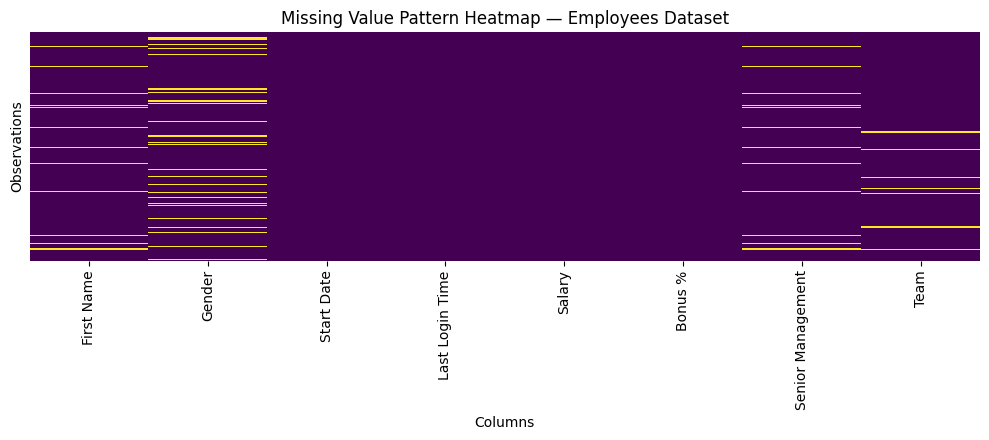


=== Missing Values After Adding Synthetic Row ===
First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64



=== Missing Values After Converting Placeholders to NaN ===
First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64

=== Imputation Comparison Summary ===
                   Before Imputation  After Imputation
First Name                        68                68
Gender                           146                 0
Start Date                         1                 1
Last Login Time                    1                 1
Salary                             1                 0
Bonus %                            1                 0
Senior Management                 68                 0
Team                              44                 0


In [4]:
# 1. Load employees.csv and inspect structure
employees_df = pd.read_csv(DATA_PATH + "employees.csv")
print("=== Employees Dataset Overview ===")
print(employees_df.info())
print("\nFirst 3 rows:")
print(employees_df.head(3))

# 2. Count missing values per column
print("\n=== Initial Missing Value Counts ===")
print(employees_df.isna().sum())

# 3. Visualize missing value patterns using Seaborn heatmap
plt.figure(figsize=(10, 4.5))
sns.heatmap(employees_df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value Pattern Heatmap — Employees Dataset", fontsize=12)
plt.xlabel("Columns")
plt.ylabel("Observations")
plt.tight_layout()
plt.show()

# 4. Create copy and append synthetic row with custom missing markers
df_work = employees_df.copy()
synthetic_entry = ["-", "na", "missing", "N/A", "?", "na", "-", "?"]
df_work.loc[len(df_work)] = synthetic_entry

# 5. Recount missing values (markers remain counted as valid non-null strings)
print("\n=== Missing Values After Adding Synthetic Row ===")
print(df_work.isna().sum())

# 6. Standardized rule: strip whitespace, lowercase, and map agreed markers to np.nan
missing_placeholders = {"-", "na", "n/a", "missing", "?", ""}
df_cleaned = df_work.apply(
    lambda col: col.mask(col.astype(str).str.strip().str.lower().isin(missing_placeholders))
)

# Restore numeric column types
df_cleaned["Salary"] = pd.to_numeric(df_cleaned["Salary"])
df_cleaned["Bonus %"] = pd.to_numeric(df_cleaned["Bonus %"])

missing_before_imputation = df_cleaned.isna().sum()
print("\n=== Missing Values After Converting Placeholders to NaN ===")
print(missing_before_imputation)

# 7. Imputation using SimpleImputer
# Median strategy for numerical features; most_frequent strategy for categorical features
# Note: First Name, Start Date, and Last Login Time are identifiers/timestamps and are kept as-is.
num_cols = ["Salary", "Bonus %"]
cat_cols = ["Gender", "Senior Management", "Team"]

num_imputer = SimpleImputer(strategy="median")
df_cleaned[num_cols] = num_imputer.fit_transform(df_cleaned[num_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
df_cleaned[cat_cols] = cat_imputer.fit_transform(df_cleaned[cat_cols])

# 8. Compare missing value counts before and after imputation
missing_after_imputation = df_cleaned.isna().sum()
comparison_table = pd.DataFrame({
    "Before Imputation": missing_before_imputation,
    "After Imputation": missing_after_imputation
})
print("\n=== Imputation Comparison Summary ===")
print(comparison_table)


-#-#- -E-x-e-r-c-i-s-e- -4- -—- -F-e-a-t-u-r-e- -S-c-a-l-i-n-g-,- -B-i-n-a-r-i-z-a-t-i-o-n-,- -a-n-d- -C-a-t-e-g-o-r-i-c-a-l- -E-n-c-o-d-i-n-g-
-#-#-#- -P-a-r-t- -A-.- -S-c-a-l-i-n-g- -a-n-d- -B-i-n-a-r-i-z-a-t-i-o-n-
-E-v-a-l-u-a-t-i-n-g- -`-S-t-a-n-d-a-r-d-S-c-a-l-e-r-`-,- -`-M-i-n-M-a-x-S-c-a-l-e-r-`-,- -`-M-a-x-A-b-s-S-c-a-l-e-r-`-,- -`-R-o-b-u-s-t-S-c-a-l-e-r-`-,- -r-o-w---w-i-s-e- -`-n-o-r-m-a-l-i-z-e-(-)-`-,- -a-n-d- -`-B-i-n-a-r-i-z-e-r-(-)-`-.-
-

In [5]:
# Original numerical matrix
M = np.array([
    [1.0, -1.0,  2.0],
    [2.0,  0.0,  0.0],
    [0.0,  1.0, -1.0]
])

print("=== Original Matrix M ===")
print(M)

# 1 & 2. Apply and display feature scalers
scalers = {
    "StandardScaler (zero mean, unit variance)": StandardScaler(),
    "MinMaxScaler (scaled to range [0, 1])": MinMaxScaler(),
    "MaxAbsScaler (scaled by max absolute value to [-1, 1])": MaxAbsScaler(),
    "RobustScaler (scaled via median and IQR)": RobustScaler()
}

for desc, scaler in scalers.items():
    transformed = scaler.fit_transform(M)
    print(f"\n--- {desc} ---")
    print(np.round(transformed, 4))

# Normalize per sample (row-wise L2 norm)
normalized_matrix = normalize(M, norm="l2")
print("\n--- normalize (Sample-wise L2 Normalization) ---")
print(np.round(normalized_matrix, 4))

# 4. Binarization with threshold = 0.0
binarizer = Binarizer(threshold=0.0)
binarized_matrix = binarizer.fit_transform(M)
print("\n--- Binarizer (threshold = 0.0) ---")
print(binarized_matrix)


=== Original Matrix M ===
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]

--- StandardScaler (zero mean, unit variance) ---
[[ 0.     -1.2247  1.3363]
 [ 1.2247  0.     -0.2673]
 [-1.2247  1.2247 -1.069 ]]

--- MinMaxScaler (scaled to range [0, 1]) ---
[[0.5    0.     1.    ]
 [1.     0.5    0.3333]
 [0.     1.     0.    ]]

--- MaxAbsScaler (scaled by max absolute value to [-1, 1]) ---
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

--- RobustScaler (scaled via median and IQR) ---
[[ 0.     -1.      1.3333]
 [ 1.      0.      0.    ]
 [-1.      1.     -0.6667]]

--- normalize (Sample-wise L2 Normalization) ---
[[ 0.4082 -0.4082  0.8165]
 [ 1.      0.      0.    ]
 [ 0.      0.7071 -0.7071]]

--- Binarizer (threshold = 0.0) ---
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


-#-#-#- -P-a-r-t- -B-.- -E-n-c-o-d-i-n-g- -C-a-t-e-g-o-r-i-c-a-l- -V-a-r-i-a-b-l-e-s-
-D-a-t-a-s-e-t-:-
--- -F-e-a-t-u-r-e-s-:- -G-e-n-d-e-r- -(-`-F-e-a-t-u-r-e- -1-`-)-,- -R-e-g-i-o-n- -(-`-F-e-a-t-u-r-e- -2-`-)-,- -B-r-o-w-s-e-r- -(-`-F-e-a-t-u-r-e- -3-`-)-
--- -T-a-r-g-e-t-:- -C-o-u-n-t-r-y- -(-`-T-a-r-g-e-t-`-)-
-

In [6]:
# Input feature array and target vector
features_data = [
    ["male", "from US", "uses Safari"],
    ["female", "from Europe", "uses Safari"],
    ["female", "from Asia", "uses Firefox"],
    ["male", "from Africa", "uses Chrome"]
]
target_data = ["US", "France", "Japan", "Algeria"]

# 1. OrdinalEncoder for input features
ordinal_encoder = OrdinalEncoder()
features_ordinal = ordinal_encoder.fit_transform(features_data)
print("=== Ordinal Encoded Input Features ===")
print(features_ordinal)

print("\nLearned Categories per Feature:")
for col_idx, categories in enumerate(ordinal_encoder.categories_):
    print(f"  Feature {col_idx + 1}: {list(categories)}")

# 2. LabelEncoder for target variable
label_encoder = LabelEncoder()
target_encoded = label_encoder.fit_transform(target_data)
print("\n=== Label Encoded Target ===")
print(f"Encoded values: {target_encoded}")
target_mapping = {label: code for code, label in enumerate(label_encoder.classes_)}
print(f"Class mapping: {target_mapping}")

# 3. OneHotEncoder for target variable
onehot_encoder = OneHotEncoder()
target_reshaped = np.array(target_data).reshape(-1, 1)
target_onehot = onehot_encoder.fit_transform(target_reshaped).toarray()

print("\n=== One-Hot Encoded Target Representation ===")
print(target_onehot)
print(f"One-Hot Categories: {list(onehot_encoder.categories_[0])}")


=== Ordinal Encoded Input Features ===
[[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]]

Learned Categories per Feature:
  Feature 1: ['female', 'male']
  Feature 2: ['from Africa', 'from Asia', 'from Europe', 'from US']
  Feature 3: ['uses Chrome', 'uses Firefox', 'uses Safari']

=== Label Encoded Target ===
Encoded values: [3 1 2 0]
Class mapping: {np.str_('Algeria'): 0, np.str_('France'): 1, np.str_('Japan'): 2, np.str_('US'): 3}

=== One-Hot Encoded Target Representation ===
[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
One-Hot Categories: [np.str_('Algeria'), np.str_('France'), np.str_('Japan'), np.str_('US')]
